# Visual Product Finder — Part 2: Image Preprocessing Pipeline

**Previous step:** in Part 1 we explored the dataset and saved `clean_products.csv` (44,441 verified products).

**This notebook:** we build a reliable pipeline that reads a product image and turns it into exactly the tensor that a pretrained **ResNet50** expects. In the next notebook this tensor goes into the network to produce an embedding.

## Why this step matters

A pretrained network is not a function that accepts "any image". It was trained with a specific input format:

* RGB images, resized and cropped to a fixed size (224×224)
* pixel values scaled to `[0, 1]`
* each colour channel normalized with the **ImageNet mean and standard deviation**

If we feed it images in a different format, it still returns numbers, but the embeddings become less meaningful and similarity search quality drops, **with no error message**. So the preprocessing must match the pretrained weights, and the **same** preprocessing must be used later in the API.

## Goals

1. Load `clean_products.csv` and rebuild image paths
2. Understand how an image becomes a tensor (shape, dtype, value range)
3. Build the preprocessing from the official ResNet50 weights and verify a manual version matches it
4. Look at what preprocessing does to our fashion images (cropping effects)
5. Build a `Dataset` and `DataLoader` that can handle all 44k images efficiently
6. Save the preprocessing settings for the next notebooks and the API

## 1. Setup

In [1]:
import os
import glob
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torchvision.models import ResNet50_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Device: cuda


### Configuration

Paths and settings are defined in one place. `WEIGHTS` selects which pretrained ResNet50 weights we prepare the images for. The preprocessing is taken from the weights themselves, so if we later compare another weights version, the pipeline adapts automatically.

Reading the transform from `ResNet50_Weights` does **not** download the model weights, so internet access is not needed in this notebook.

In [2]:
DATASET_PATH = Path("/kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset/fashion-dataset")
IMAGE_DIR = DATASET_PATH / "images"
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

WEIGHTS = ResNet50_Weights.IMAGENET1K_V2

BATCH_SIZE = 64
NUM_WORKERS = 4

def find_clean_csv(name="clean_products.csv"):
    # Look in the working folder and in notebook outputs attached as Input (fixed-depth patterns only)
    patterns = [f"/kaggle/working/{name}", f"/kaggle/input/*/{name}",
                f"/kaggle/input/*/*/{name}", f"/kaggle/input/*/*/*/{name}", f"./{name}"]
    for pattern in patterns:
        hits = sorted(glob.glob(pattern))
        if hits:
            return Path(hits[0])
    raise FileNotFoundError(
        f"{name} not found. In Kaggle: Add Input -> Your Work / Notebook Output -> select the EDA notebook."
    )

CLEAN_CSV = find_clean_csv()
print("Using:", CLEAN_CSV)

Using: /kaggle/input/notebooks/tahazarei/vpf-01-fashion-dataset-eda/clean_products.csv


## 2. Loading the Clean Product Table

We load the table created in Part 1 and rebuild `image_path`. (We saved only the filename `image`, because absolute paths change between environments.)

Then we run quick sanity checks, since everything after this depends on this table being consistent.

In [3]:
clean_df = pd.read_csv(CLEAN_CSV)
clean_df["image_path"] = clean_df["image"].apply(lambda f: IMAGE_DIR / f)

files_on_disk = {e.name for e in os.scandir(IMAGE_DIR)}

print("Products:", len(clean_df))
print("Unique IDs:", clean_df["id"].is_unique)
print("All image files exist:", clean_df["image"].isin(files_on_disk).all())
clean_df.head()

Products: 44441
Unique IDs: True
All image files exist: True


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image,image_path
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt,15970.jpg,/kaggle/input/datasets/paramaggarwal/fashion-p...
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans,39386.jpg,/kaggle/input/datasets/paramaggarwal/fashion-p...
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch,59263.jpg,/kaggle/input/datasets/paramaggarwal/fashion-p...
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants,21379.jpg,/kaggle/input/datasets/paramaggarwal/fashion-p...
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt,53759.jpg,/kaggle/input/datasets/paramaggarwal/fashion-p...


## 3. From Image File to Tensor

Before using any library transform, let's look at what an image looks like to a neural network. We load one product and inspect it at each representation.

In [4]:
sample_row = clean_df.sample(1, random_state=SEED).iloc[0]
print(sample_row["productDisplayName"], "|", sample_row["articleType"])

img = Image.open(sample_row["image_path"]).convert("RGB")
arr = np.array(img)
tensor = TF.to_tensor(img)

print("\nPIL image   -> size (W, H):", img.size, "| mode:", img.mode)
print("NumPy array -> shape (H, W, C):", arr.shape, "| dtype:", arr.dtype, "| range:", arr.min(), "-", arr.max())
print("Tensor      -> shape (C, H, W):", tuple(tensor.shape), "| dtype:", tensor.dtype,
      "| range:", round(tensor.min().item(), 2), "-", round(tensor.max().item(), 2))

Doodle Girl Ballet School Black Tops | Tops

PIL image   -> size (W, H): (1800, 2400) | mode: RGB
NumPy array -> shape (H, W, C): (2400, 1800, 3) | dtype: uint8 | range: 0 - 255
Tensor      -> shape (C, H, W): (3, 2400, 1800) | dtype: torch.float32 | range: 0.0 - 1.0


**What changed:**

| Representation | Layout | Type | Values |
|----------------|--------|------|--------|
| PIL / NumPy | height × width × channels | `uint8` | 0–255 |
| PyTorch tensor | **channels × height × width** | `float32` | **0–1** |

`to_tensor` does three things at once: it moves the channel axis to the front, converts to float, and divides by 255. Neural networks in PyTorch expect the channels-first layout.

We also call `.convert("RGB")` on every image. All our images are already RGB (checked in Part 1), but this makes the pipeline safe for grayscale or RGBA images that might appear in new uploads through the API.

## 4. The Official ResNet50 Preprocessing

Instead of guessing the preprocessing values, we ask the pretrained weights what they expect.

In [5]:
preprocess = WEIGHTS.transforms()
print(preprocess)

resize_size  = preprocess.resize_size[0]
crop_size    = preprocess.crop_size[0]
mean         = preprocess.mean
std          = preprocess.std
interpolation = preprocess.interpolation

print("\nResize (shorter side):", resize_size)
print("Center crop:", crop_size)
print("Mean:", mean)
print("Std:", std)
print("Interpolation:", interpolation)

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

Resize (shorter side): 232
Center crop: 224
Mean: [0.485, 0.456, 0.406]
Std: [0.229, 0.224, 0.225]
Interpolation: InterpolationMode.BILINEAR


### What each step does

1. **Resize** the shorter side to `resize_size` while keeping the aspect ratio
2. **Center crop** to `crop_size × crop_size`, the fixed size the network takes
3. **Convert to tensor** (channels first, float, 0–1)
4. **Normalize** each channel: `(x - mean) / std`

The mean and std are the ImageNet statistics, since the network was trained on ImageNet. After normalization, values are roughly centred around 0 and fall approximately between -2 and +2.5, which is the numeric range the network saw during training.

Let's apply the steps one by one to see them.

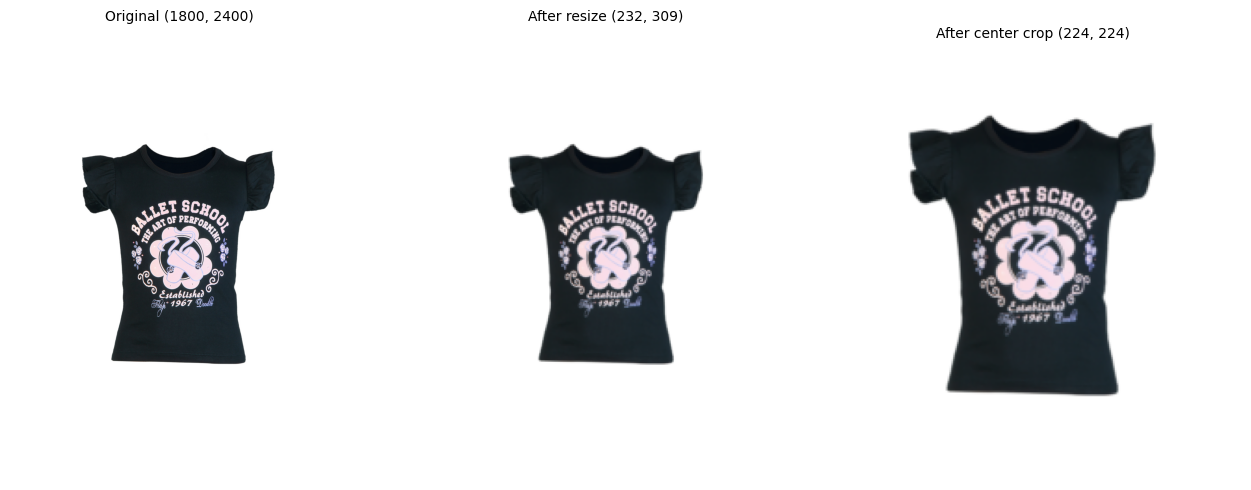

Before normalize -> min/max/mean: 0.01 1.0 0.8
After normalize  -> min/max/mean: -2.07 2.64 1.55
Final tensor shape: (3, 224, 224)


In [6]:
resized = TF.resize(img, [resize_size], interpolation=interpolation)
cropped = TF.center_crop(resized, [crop_size])
as_tensor = TF.to_tensor(cropped)
normalized = TF.normalize(as_tensor, mean=mean, std=std)

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, im, title in zip(axes, [img, resized, cropped],
                         [f"Original {img.size}", f"After resize {resized.size}", f"After center crop {cropped.size}"]):
    ax.imshow(im)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Before normalize -> min/max/mean:", round(as_tensor.min().item(), 2), round(as_tensor.max().item(), 2), round(as_tensor.mean().item(), 2))
print("After normalize  -> min/max/mean:", round(normalized.min().item(), 2), round(normalized.max().item(), 2), round(normalized.mean().item(), 2))
print("Final tensor shape:", tuple(normalized.shape))

### Does our manual pipeline match the official one?

We build the same pipeline manually with `torchvision.transforms.Compose`. This shows exactly what the official transform does, and gives a version we can reuse in the API. Then we verify both produce identical tensors.

In [7]:
manual_preprocess = T.Compose([
    T.Resize(resize_size, interpolation=interpolation),
    T.CenterCrop(crop_size),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

out_official = preprocess(img)
out_manual = manual_preprocess(img)

print("Same shape:", out_official.shape == out_manual.shape)
print("Max absolute difference:", (out_official - out_manual).abs().max().item())
print("Tensors match:", bool(torch.allclose(out_official, out_manual, atol=1e-4)))

Same shape: True
Max absolute difference: 0.0
Tensors match: True


Both pipelines produce the same tensor. From now on we use `manual_preprocess`, because it is explicit and does not depend on the weights object at inference time.

## 5. How Preprocessing Affects Fashion Images

Center cropping is a reasonable choice for ImageNet, where the object is usually in the middle. Our product images have a **3:4 portrait ratio**, so after resizing the shorter side, the crop removes part of the **top and bottom**. Is important content lost?

We compare three versions on random products: the original, the standard center crop, and a "squashed" version where the full image is resized to 224×224 (the whole product is kept, but it is distorted).

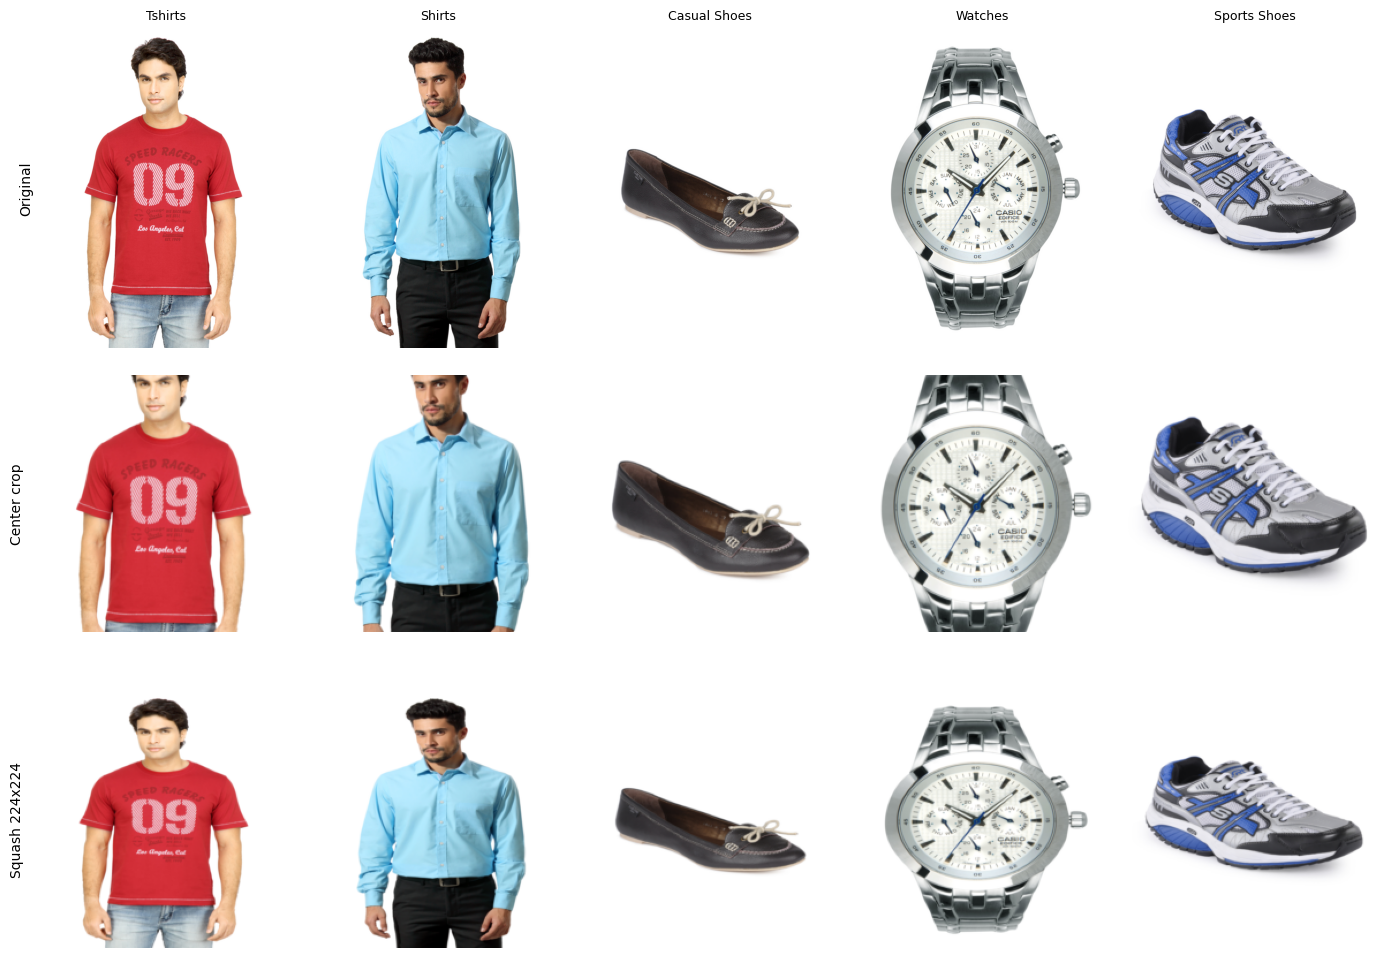

In [8]:
top_types = clean_df["articleType"].value_counts().head(5).index
examples = pd.concat([clean_df[clean_df["articleType"] == t].sample(1, random_state=SEED + i)
                      for i, t in enumerate(top_types)])

fig, axes = plt.subplots(3, 5, figsize=(14, 10))
for col, (_, row) in enumerate(examples.iterrows()):
    im = Image.open(row["image_path"]).convert("RGB")
    crop = TF.center_crop(TF.resize(im, [resize_size], interpolation=interpolation), [crop_size])
    squash = TF.resize(im, [crop_size, crop_size], interpolation=interpolation)

    axes[0, col].imshow(im);     axes[0, col].set_title(row["articleType"], fontsize=9)
    axes[1, col].imshow(crop)
    axes[2, col].imshow(squash)
    for r in range(3):
        axes[r, col].axis("off")

axes[0, 0].text(-0.05, 0.5, "Original", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.05, 0.5, "Center crop", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
axes[2, 0].text(-0.05, 0.5, "Squash 224x224", transform=axes[2, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout()
plt.show()

### Decision

We use the **standard center-crop preprocessing as our baseline**, because it matches how the pretrained weights were trained and is the recommended setup.

The comparison above helps us notice cases where the crop cuts off useful parts of a product (for example, the top or bottom of long items). In the evaluation notebook, if we see retrieval failures caused by this, we can test the squash or padding alternatives and compare results. We do not make this change now without evidence.

## 6. Dataset and DataLoader

We need to process 44,441 images, and the images are large (mostly 1080×1440 and 1800×2400). Reading and resizing them one at a time would leave the GPU waiting. So we use:

* a **`Dataset`** that loads and preprocesses one image
* a **`DataLoader`** that does this in parallel worker processes and groups images into batches

### Handling bad images

If an image fails to load, we do **not** crash a long run in the middle. The dataset returns a zero tensor with `ok = False`, so the batch keeps its shape and the failure can be recorded. In the feature extraction notebook we will log those indices and exclude them from the catalog.

The dataset also returns the row `index`, so every embedding can be matched back to the exact row of the product table. This guarantees the embeddings and product rows stay in the same order, which the API will depend on later.

In [9]:
class ProductImageDataset(Dataset):
    def __init__(self, dataframe, transform, crop_size=224):
        self.paths = dataframe["image_path"].tolist()
        self.transform = transform
        self.crop_size = crop_size

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            with Image.open(self.paths[idx]) as im:
                tensor = self.transform(im.convert("RGB"))
            return tensor, idx, True
        except Exception as e:
            print(f"Failed to load index {idx}: {e}")
            return torch.zeros(3, self.crop_size, self.crop_size), idx, False

dataset = ProductImageDataset(clean_df, manual_preprocess, crop_size)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,                       # keep the same order as the product table
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print("Dataset size:", len(dataset))
print("Batches per epoch:", len(loader))

Dataset size: 44441
Batches per epoch: 695


### Testing one batch

We check shape, data type, value statistics and that the batch moves to the GPU. After normalization, the mean should be near zero and the std near 1 (roughly, since fashion images have lots of white background, which pushes values higher).

In [10]:
images, indices, ok = next(iter(loader))

print("Batch shape:", tuple(images.shape), "(batch, channels, height, width)")
print("Dtype:", images.dtype)
print("Value range:", round(images.min().item(), 2), "to", round(images.max().item(), 2))
print("Mean / std:", round(images.mean().item(), 3), "/", round(images.std().item(), 3))
print("All images loaded:", bool(ok.all()))
print("First indices:", indices[:8].tolist())

images_gpu = images.to(device, non_blocking=True)
print("Batch is on:", images_gpu.device)

Batch shape: (64, 3, 224, 224) (batch, channels, height, width)
Dtype: torch.float32
Value range: -2.12 to 2.64
Mean / std: 1.41 / 1.433
All images loaded: True
First indices: [0, 1, 2, 3, 4, 5, 6, 7]
Batch is on: cuda:0


### Looking at the processed images

Normalized tensors look strange if plotted directly. To visually verify the pipeline, we **denormalize** (reverse the normalization) and display the batch. If the images look correct, the pipeline preserves the visual content.

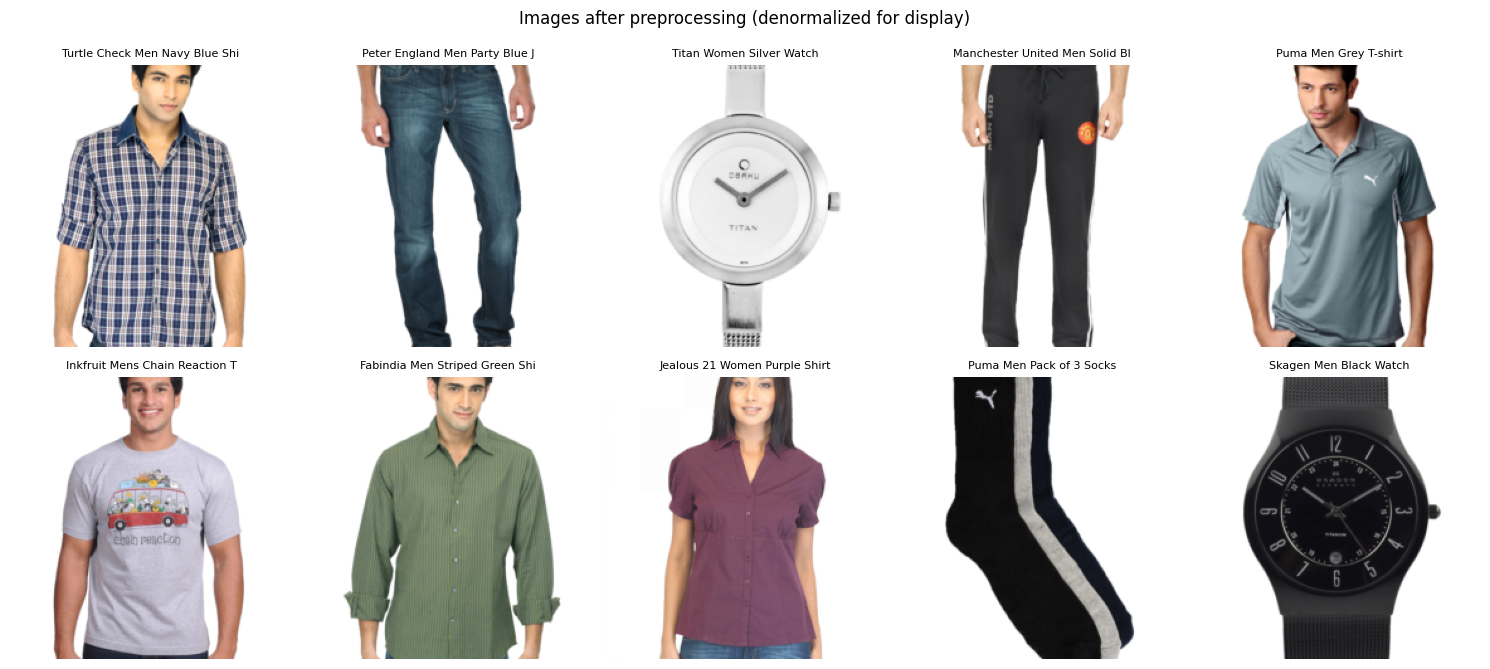

In [11]:
def denormalize(batch, mean=mean, std=std):
    m = torch.tensor(mean).view(1, 3, 1, 1)
    s = torch.tensor(std).view(1, 3, 1, 1)
    return (batch.cpu() * s + m).clamp(0, 1)

shown = denormalize(images[:10])

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for ax, tensor_img, idx in zip(axes.flatten(), shown, indices[:10]):
    ax.imshow(tensor_img.permute(1, 2, 0).numpy())   # (C,H,W) -> (H,W,C) for matplotlib
    ax.set_title(str(clean_df.loc[idx.item(), "productDisplayName"])[:30], fontsize=8)
    ax.axis("off")
plt.suptitle("Images after preprocessing (denormalized for display)", fontsize=12)
plt.tight_layout()
plt.show()

## 7. Loading Speed

In the next notebook, extracting embeddings requires one pass over all 44,441 images. We measure how fast our loader is so we can plan that run. The first batch is excluded because it includes the worker start-up time.

In [12]:
n_batches = 10
count = 0
start = None

for i, (x, idx, ok) in enumerate(loader):
    if i == 1:
        start = time.time()          # start timing after the first batch
    elif i > 1:
        count += x.shape[0]
    if i == n_batches:
        break

elapsed = time.time() - start
speed = count / elapsed
print(f"Speed: {speed:.1f} images/second")
print(f"Estimated time for one full pass over {len(dataset):,} images: {len(dataset) / speed / 60:.1f} minutes")

Speed: 49.4 images/second
Estimated time for one full pass over 44,441 images: 15.0 minutes


If this estimate is high, the bottleneck is image decoding and resizing on the CPU, not the model. Options we can use later: more workers, or pre-generating smaller copies of the images once.

## 8. Saving the Preprocessing Configuration

The API must preprocess uploaded images **exactly** like we preprocess the catalog. Otherwise, a query image and a catalog image of the same product would end up with different embeddings. We save the settings now, and they will become part of `model_config.json`.

In [13]:
preprocess_config = {
    "weights": str(WEIGHTS),
    "resize_size": resize_size,
    "crop_size": crop_size,
    "mean": list(mean),
    "std": list(std),
    "interpolation": interpolation.value,
    "convert_mode": "RGB",
}

with open(OUTPUT_DIR / "preprocess_config.json", "w") as f:
    json.dump(preprocess_config, f, indent=2)

print(json.dumps(preprocess_config, indent=2))

{
  "weights": "ResNet50_Weights.IMAGENET1K_V2",
  "resize_size": 232,
  "crop_size": 224,
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "interpolation": "bilinear",
  "convert_mode": "RGB"
}


## 9. Summary

> Fill in the measured values after running the notebook.

| Item | Value |
|------|-------|
| Products loaded | 44,441 |
| Pretrained weights prepared for | ResNet50 `IMAGENET1K_V2` |
| Resize / crop | 232 / 224 |
| Tensor shape per image | (3, 224, 224) |
| Batch shape | (64, 3, 224, 224) |
| Loading speed | ... images/second |
| Estimated full-pass time | ... minutes |
| Images that failed to load | 0 (expected) |

**Key points**

* The pipeline reads, converts to RGB, resizes, center-crops, converts to a tensor and normalizes with ImageNet statistics, matching the pretrained weights.
* The manual `Compose` pipeline gives the same output as the official weights transform, so it can be reused in the API.
* Center cropping removes part of the top and bottom of 3:4 product images. It is kept as the baseline; alternatives will be tested only if the evaluation shows a problem.
* The dataset returns the row index with every image, so embeddings can always be matched to the correct product.

## Next: Part 3 — Feature Extraction with ResNet50

We load the pretrained ResNet50, remove its final classification layer, and run all catalog images through it to get one embedding vector per product.

> **Note:** loading pretrained weights downloads them from the internet. In Kaggle, turn on **Internet** in the notebook settings for that notebook (or provide the weights as an input dataset).